In [ ]:
# =====================================================================================
#  CELL 1 — CONFIGURATION.  This is the only cell you need to edit.
# =====================================================================================
class CFG:
    # ------------------------------------------------------------------------- paths
    DRIVE_ROOT = "/content/drive/MyDrive"
    TRAIN_DIR  = DRIVE_ROOT + "/dataset/Win64_train"      # EMBER-2018 training files
    TEST_DIR   = DRIVE_ROOT + "/dataset/Win64_test"       # EMBER-2018 test files
    OUTPUT_DIR = DRIVE_ROOT + "/results/ember2018_xai"    # figures, tables, per-seed results
    CACHE_DIR  = DRIVE_ROOT + "/cache/ember2018"          # vectorised arrays (used for raw .jsonl input only)

    # ------------------------------------------------------------- number of samples
    N_TRAIN_SAMPLES = None       # labelled training files to load (None = all 600,000)
    N_TEST_SAMPLES  = None       # labelled test files to load     (None = all 200,000)
    VAL_FRACTION    = 0.10       # stratified validation split, taken from the training files only
    N_DONORS        = 100_000    # donor pool of the conditional imputer (training files only)
    N_EVAL          = 5_000      # |D_ev|: test files used for L(S), unique bits, interaction, ablation
    N_EVAL_SHAPLEY  = 1_000      # part of D_ev used by Conditional SHAP and SAGE (they need all 2^G subsets)
    N_TREESHAP      = 20_000     # test files used by TreeSHAP (on the GPU)
    N_TREESHAP_CPU  = 2_000      # used only if GPU TreeSHAP is not possible (e.g. very deep LightGBM trees)
    N_BACKGROUND    = 512        # SAGE: number of marginal background files (from the donor pool)

    # ----------------------------------------------------------------------- dataset
    # EMBER-2018 (feature version 2) has 9 groups and 2,381 columns, in this order.
    FEATURE_GROUPS = [
        ("histogram", 256), ("byteentropy", 256), ("strings", 104), ("general", 10), ("header", 62),
        ("section", 255), ("imports", 1280), ("exports", 128), ("datadirectories", 30),
    ]
    # Per-group term of the hybrid distance (Stage 3). Every term is scaled to [0, 1].
    #   "jsd"              Jensen-Shannon divergence (bits)         -> distribution-like groups
    #   "euclidean"        Euclidean distance on standardised values -> dense numeric groups
    #   "jaccard_set"      Jaccard distance on the set of non-zero (hashed) entries -> set-valued groups
    #   "jaccard_weighted" generalised Jaccard for non-negative numeric vectors (same as jaccard_set on 0/1 data)
    GROUP_DISTANCE = {
        "histogram": "jsd", "byteentropy": "jsd",
        "general": "euclidean", "header": "euclidean", "section": "euclidean", "datadirectories": "euclidean",
        "imports": "jaccard_set", "exports": "jaccard_set", "strings": "jaccard_weighted",
    }

    # -------------------------------------------------------------------- classifier
    MODEL                 = "xgboost"            # "xgboost" or "lightgbm"
    LEARNING_RATE         = 0.05
    XGB_MAX_DEPTH         = 8
    LGBM_NUM_LEAVES       = 255
    LGBM_DEVICE_TYPE      = "gpu"                # LightGBM training device: "gpu" (OpenCL), "cuda" or "cpu"
    MAX_BIN               = 256
    NUM_BOOST_ROUND       = 1000
    EARLY_STOPPING_ROUNDS = 50
    SEEDS                 = [2026, 2027, 2028]   # one full run per seed; use [2026] for a quick run

    # ----------------------------------------------------- conditional imputer (Stage 3)
    K_DONORS            = 512     # k nearest donors
    TAU                 = 32.0    # bandwidth of the donor weights w_ij ~ exp(-Delta_S / tau)
    EUCLID_LOG1P        = True    # signed log1p before standardising (sizes, addresses, time stamps)
    EUCLID_REF_QUANTILE = 0.99    # Euclidean distances are divided by this quantile, then clipped to [0, 1]

    # ----------------------------------------------------------------- attributions
    COND_SHAP_VALUE          = "loss"   # "loss": Shapley on -cross-entropy (bits) | "logit": mean |Shapley| on log2-odds
    EXACT_SHAPLEY_MAX_GROUPS = 12       # exact Shapley over all 2^G subsets up to this G, else permutation sampling
    N_PERMUTATIONS           = 64       # permutations used when Shapley values are sampled
    TREESHAP_UNIT            = "nats"   # "nats" (log-odds, as returned by TreeSHAP) or "bits" (log2-odds)

    # -------------------------------------------------------------------------- GPU
    DEVICE            = "cuda"
    REQUIRE_A100      = True            # stop if the runtime is not an NVIDIA A100
    PRED_BATCH_ROWS   = 262_144         # rows per classifier call (2.5 GB of float32 at 2,381 columns)
    PAIRWISE_ELEMS    = 1_000_000_000   # largest temporary tensor (elements) in the pairwise distance kernels
    DIST_CACHE_GPU_GB = 20              # keep the distance cache on the GPU up to this size, else in host RAM

    # ------------------------------------------------------------------ run control
    RESUME    = True     # reuse per-seed results already saved in OUTPUT_DIR for the same settings
    DATA_SEED = 0        # seed of the sub-sampling done while loading (N_TRAIN_SAMPLES / N_TEST_SAMPLES)
    N_WORKERS = None     # processes used to vectorise raw .jsonl files (None = all CPU cores)
    LOG_EVERY = 100      # print the validation loss every this many boosting rounds

    # ---------------------------------------------------------------------- figures
    FIG_FONT_FAMILY    = "serif"
    FIG_FONT_SIZE      = 12
    FIG_DPI            = 300
    FIG_FORMATS        = ("pdf", "png")
    HEATMAP_CMAP       = "RdBu_r"       # diverging: red = synergy, blue = redundancy, near-white = 0
    HEATMAP_ORDER      = "strength"     # "strength" (total |interaction|), "importance" (unique bits) or "native"
    HEATMAP_ANNOT_SIZE = 10
    HEATMAP_DIAG_COLOR = "#EBEBEB"
    COLOR_AUPRC        = "#0072B2"      # colour-blind-safe blue
    COLOR_AUROC        = "#D55E00"      # colour-blind-safe orange
    COLOR_BASELINE     = "#222222"
    ABLATION_MARKERS   = True           # circles / squares as in the reference figure; False = plain lines

In [ ]:
import os, sys, subprocess, importlib, importlib.util, importlib.metadata as _md

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def _installed(dist):
    try:
        return _md.version(dist)
    except _md.PackageNotFoundError:
        return None


def _pip(*specs, required=True):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *specs])
    if r.returncode != 0 and required:
        raise RuntimeError(f"pip install failed for {specs}")
    importlib.invalidate_caches()


_v = _installed("xgboost")
if _v is None or tuple(int(t) for t in _v.split(".")[:2]) < (2, 0):
    _pip("xgboost>=2.1")                       # device="cuda" needs XGBoost >= 2.0
if CFG.MODEL == "lightgbm" and _installed("lightgbm") is None:
    _pip("lightgbm>=4.0")
if _installed("orjson") is None:
    _pip("orjson", required=False)             # optional: faster JSON parsing for raw .jsonl input
if _installed("tqdm") is None:
    _pip("tqdm")

import torch

if CFG.DEVICE == "cuda":
    if not torch.cuda.is_available():
        raise RuntimeError("No GPU found. Use Runtime -> Change runtime type -> A100 GPU.")
    _gpu = torch.cuda.get_device_name(0)
    _gb = torch.cuda.get_device_properties(0).total_memory / 2**30
    print(f"GPU: {_gpu} ({_gb:.0f} GB)")
    if CFG.REQUIRE_A100 and "A100" not in _gpu:
        raise RuntimeError(f"This notebook is written for the NVIDIA A100, but the runtime has '{_gpu}'. "
                           "Switch the runtime to A100 (or set CFG.REQUIRE_A100 = False at your own risk).")
    try:
        import cupy as cp                      # zero-copy hand-over of GPU tensors to XGBoost
    except Exception:
        _pip(f"cupy-cuda{(torch.version.cuda or '12').split('.')[0]}x", required=False)
        try:
            import cupy as cp
        except Exception as e:
            cp = None
            print("WARNING: CuPy is not available; classifier calls will copy through host memory (slow).", e)
else:
    cp = None
    print(f"DEVICE = {CFG.DEVICE!r}: running without a GPU (meant for small tests only).")

for _d in (CFG.OUTPUT_DIR, CFG.CACHE_DIR):
    os.makedirs(_d, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA A100-SXM4-40GB (39 GB)


In [ ]:
import gc, glob, hashlib, json, math, re, time
import multiprocessing as mp

import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib
import matplotlib.colors
import matplotlib.ticker
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

print(f"torch {torch.__version__} | xgboost {xgb.__version__} | numpy {np.__version__}")

DEV = torch.device(CFG.DEVICE)
LN2 = math.log(2.0)

# ---- Stage 1: the grouped-feature setting -----------------------------------------
GROUP_NAMES = [name for name, _ in CFG.FEATURE_GROUPS]
GROUP_DIMS = [dim for _, dim in CFG.FEATURE_GROUPS]
_off = np.concatenate([[0], np.cumsum(GROUP_DIMS)]).astype(int)
GROUP_SLICES = [slice(int(_off[i]), int(_off[i + 1])) for i in range(len(GROUP_NAMES))]
N_FEATURES = int(_off[-1])
G = len(GROUP_NAMES)
FULL_MASK = (1 << G) - 1            # a subset S of groups is a bit mask: bit g set = group g is observed

assert set(CFG.GROUP_DISTANCE) == set(GROUP_NAMES), "GROUP_DISTANCE must name exactly the groups in FEATURE_GROUPS"
assert CFG.N_EVAL_SHAPLEY <= CFG.N_EVAL, "N_EVAL_SHAPLEY cannot be larger than N_EVAL"
print(f"{G} feature groups, {N_FEATURES} columns:", ", ".join(f"{n}({d})" for n, d in CFG.FEATURE_GROUPS))


def ce_bits(y, p, eps=1e-7):
    """Per-sample binary cross-entropy in bits (the summand of Eq. 5)."""
    p = np.clip(np.asarray(p, dtype=np.float64), eps, 1.0 - eps)
    y = np.asarray(y, dtype=np.float64)
    return -(y * np.log2(p) + (1.0 - y) * np.log2(1.0 - p))


def mean_se(a):
    """Mean and standard error over the first axis."""
    a = np.asarray(a, dtype=np.float64)
    return a.mean(axis=0), a.std(axis=0, ddof=1) / math.sqrt(a.shape[0])


def stratified_indices(y, n, rng):
    """Sorted indices of a class-stratified random sample of size n (all indices if n is None or too large)."""
    y = np.asarray(y)
    if n is None or n >= len(y):
        return np.arange(len(y))
    classes, counts = np.unique(y, return_counts=True)
    exact = counts * (n / len(y))
    alloc = np.floor(exact).astype(int)
    for j in np.argsort(-(exact - alloc))[: n - alloc.sum()]:
        alloc[j] += 1
    picks = [rng.choice(np.flatnonzero(y == c), size=a, replace=False) for c, a in zip(classes, alloc)]
    return np.sort(np.concatenate(picks))


def free_gpu():
    gc.collect()
    if DEV.type == "cuda":
        torch.cuda.empty_cache()
        if cp is not None:
            cp.get_default_memory_pool().free_all_blocks()

torch 2.14.1+cu130 | xgboost 3.4.1 | numpy 2.4.6
9 feature groups, 2381 columns: histogram(256), byteentropy(256), strings(104), general(10), header(62), section(255), imports(1280), exports(128), datadirectories(30)


In [ ]:
try:
    import orjson
    _loads = orjson.loads
except Exception:
    _loads = json.loads

from sklearn.feature_extraction import FeatureHasher

_HASHERS = {}
_RAW_GROUPS = ["histogram", "byteentropy", "strings", "general", "header", "section", "imports", "exports",
               "datadirectories"]
_GENERAL_KEYS = ["size", "vsize", "has_debug", "exports", "imports", "has_relocations", "has_resources",
                 "has_signature", "has_tls", "symbols"]
_OPTIONAL_KEYS = ["major_image_version", "minor_image_version", "major_linker_version", "minor_linker_version",
                  "major_operating_system_version", "minor_operating_system_version", "major_subsystem_version",
                  "minor_subsystem_version", "sizeof_code", "sizeof_headers", "sizeof_heap_commit"]


def _hash(dim, kind, samples):
    key = (dim, kind)
    if key not in _HASHERS:
        _HASHERS[key] = FeatureHasher(n_features=dim, input_type=kind)
    return _HASHERS[key].transform(samples).toarray()


def vectorize_ember2018(objs):
    """Raw EMBER-2018 records -> float32 matrix [n, 2381].

    Same columns and hashing as ember.PEFeatureExtractor(feature_version=2).process_raw_features:
    histogram, byteentropy, strings, general, header, section, imports, exports, datadirectories.
    """
    n = len(objs)

    def normalised(key):
        c = np.asarray([o[key] for o in objs], dtype=np.float32)
        s = c.sum(axis=1, keepdims=True)
        return c / np.where(s > 0, s, 1.0)

    strs = np.zeros((n, 104), dtype=np.float64)
    for i, o in enumerate(objs):
        s = o["strings"]
        div = float(s["printables"]) if s["printables"] > 0 else 1.0
        strs[i, 0:3] = (s["numstrings"], s["avlength"], s["printables"])
        strs[i, 3:99] = np.asarray(s["printabledist"], dtype=np.float64) / div
        strs[i, 99:104] = (s["entropy"], s["paths"], s["urls"], s["registry"], s["MZ"])

    general = np.asarray([[o["general"][k] for k in _GENERAL_KEYS] for o in objs], dtype=np.float64)

    coff = [o["header"]["coff"] for o in objs]
    opt = [o["header"]["optional"] for o in objs]
    header = np.hstack([
        np.asarray([[c["timestamp"]] for c in coff], dtype=np.float64),
        _hash(10, "string", [[c["machine"]] for c in coff]),
        _hash(10, "string", [c["characteristics"] for c in coff]),
        _hash(10, "string", [[p["subsystem"]] for p in opt]),
        _hash(10, "string", [p["dll_characteristics"] for p in opt]),
        _hash(10, "string", [[p["magic"]] for p in opt]),
        np.asarray([[p[k] for k in _OPTIONAL_KEYS] for p in opt], dtype=np.float64),
    ])

    secs = [o["section"] for o in objs]
    sec_general = np.asarray([[
        len(s["sections"]),
        sum(1 for x in s["sections"] if x["size"] == 0),
        sum(1 for x in s["sections"] if x["name"] == ""),
        sum(1 for x in s["sections"] if "MEM_READ" in x["props"] and "MEM_EXECUTE" in x["props"]),
        sum(1 for x in s["sections"] if "MEM_WRITE" in x["props"]),
    ] for s in secs], dtype=np.float64)
    section = np.hstack([
        sec_general,
        _hash(50, "pair", [[(x["name"], x["size"]) for x in s["sections"]] for s in secs]),
        _hash(50, "pair", [[(x["name"], x["entropy"]) for x in s["sections"]] for s in secs]),
        _hash(50, "pair", [[(x["name"], x["vsize"]) for x in s["sections"]] for s in secs]),
        # the released EMBER vectors hash the entry-point name character by character
        _hash(50, "string", [list(s["entry"]) for s in secs]),
        _hash(50, "string", [[p for x in s["sections"] for p in x["props"] if x["name"] == s["entry"]]
                             for s in secs]),
    ])

    imps = [o["imports"] for o in objs]
    imports = np.hstack([
        _hash(256, "string", [list(set(lib.lower() for lib in d.keys())) for d in imps]),
        _hash(1024, "string", [[lib.lower() + ":" + e for lib, el in d.items() for e in el] for d in imps]),
    ])
    exports = _hash(128, "string", [o["exports"] for o in objs])

    datadirs = np.zeros((n, 30), dtype=np.float64)
    for i, o in enumerate(objs):
        for j, d in enumerate(o["datadirectories"][:15]):
            datadirs[i, 2 * j] = d["size"]
            datadirs[i, 2 * j + 1] = d["virtual_address"]

    with np.errstate(over="ignore"):
        return np.hstack([normalised("histogram"), normalised("byteentropy"), strs, general, header, section,
                          imports, exports, datadirs]).astype(np.float32)


def _vectorize_lines(lines):
    objs = [_loads(line) for line in lines]
    return vectorize_ember2018(objs), np.asarray([o["label"] for o in objs], dtype=np.int8)


_LABEL_RE = re.compile(rb'"label"\s*:\s*(-?\d+)')


def _load_jsonl(files, n_take, rng, tag):
    if N_FEATURES != 2381 or GROUP_NAMES != _RAW_GROUPS:
        raise ValueError("Raw .jsonl input is only supported for the EMBER-2018 layout (9 groups, 2,381 columns).")
    sig = hashlib.md5(json.dumps([[os.path.basename(f), os.path.getsize(f)] for f in files]
                                 + [n_take, CFG.DATA_SEED]).encode()).hexdigest()[:10]
    fx = os.path.join(CFG.CACHE_DIR, f"{tag}_{sig}_X.npy")
    fy = os.path.join(CFG.CACHE_DIR, f"{tag}_{sig}_y.npy")
    if os.path.exists(fx) and os.path.exists(fy):
        print(f"  {tag}: loading cached vectors {fx}")
        return np.load(fx), np.load(fy)

    # pass 1: read the label of every line (no JSON parsing)
    labels, first = [], None
    for f in files:
        with open(f, "rb") as fh:
            for line in tqdm(fh, desc=f"  scanning {os.path.basename(f)}", unit=" lines", leave=False):
                m = _LABEL_RE.search(line) if line.strip() else None
                labels.append(int(m.group(1)) if m else -9)
                if first is None and m:
                    first = line
    labels = np.asarray(labels, dtype=np.int16)
    keys = set(_loads(first).keys())
    if not set(_RAW_GROUPS) <= keys:
        raise ValueError(f"{files[0]} is not EMBER-2018 raw features; missing {sorted(set(_RAW_GROUPS) - keys)}")
    extra = keys & {"richheader", "authenticode", "pefilewarnings"}
    if extra:
        raise ValueError(f"{files[0]} looks like EMBER-2024 raw features (found {sorted(extra)}). "
                         "This notebook vectorises EMBER-2018 (feature version 2) only.")
    labelled = np.flatnonzero((labels == 0) | (labels == 1))
    sel = labelled[stratified_indices(labels[labelled], n_take, rng)]
    keep = np.zeros(len(labels), dtype=bool)
    keep[sel] = True

    # pass 2: parse and vectorise the selected lines in parallel
    def chunks(size=512):
        buf, g = [], 0
        for f in files:
            with open(f, "rb") as fh:
                for line in fh:
                    if keep[g]:
                        buf.append(line)
                        if len(buf) == size:
                            yield buf
                            buf = []
                    g += 1
        if buf:
            yield buf

    X = np.empty((len(sel), N_FEATURES), dtype=np.float32)
    y = np.empty(len(sel), dtype=np.int8)
    pos = 0
    workers = CFG.N_WORKERS or os.cpu_count() or 1
    with mp.get_context("fork").Pool(workers) as pool, tqdm(total=len(sel), desc=f"  vectorising {tag}") as bar:
        for Xc, yc in pool.imap(_vectorize_lines, chunks()):
            X[pos:pos + len(yc)] = Xc
            y[pos:pos + len(yc)] = yc
            pos += len(yc)
            bar.update(len(yc))
    np.save(fx, X)
    np.save(fy, y)
    print(f"  {tag}: cached vectors in {fx}")
    return X, y


def _take_rows(X_src, y_raw, n_take, rng, tag):
    """Keep labelled rows, take a stratified sample, and read the selected rows chunk by chunk."""
    y_raw = np.asarray(y_raw).ravel()
    if X_src.shape[0] != len(y_raw) or X_src.shape[1] != N_FEATURES:
        raise ValueError(f"{tag}: features have shape {X_src.shape} but {len(y_raw)} labels and "
                         f"{N_FEATURES} columns were expected. Edit CFG.FEATURE_GROUPS if the layout differs.")
    labelled = np.flatnonzero((y_raw == 0) | (y_raw == 1))
    sel = labelled[stratified_indices(y_raw[labelled], n_take, rng)]
    X = np.empty((len(sel), N_FEATURES), dtype=np.float32)
    step, pos = 50_000, 0
    for a in tqdm(range(0, len(y_raw), step), desc=f"  reading {tag}", leave=False):
        i0, i1 = np.searchsorted(sel, a), np.searchsorted(sel, a + step)
        if i1 > i0:
            X[pos:pos + i1 - i0] = np.asarray(X_src[a:a + step], dtype=np.float32)[sel[i0:i1] - a]
            pos += i1 - i0
    return X, y_raw[sel].astype(np.int8)


def _find_dat_pair(files):
    """Features/labels pair among raw float32 files: the features file is N_FEATURES times larger."""
    size = {f: os.path.getsize(f) for f in files}
    for fx in sorted(files, key=lambda f: -size[f]):
        for fy in files:
            if fy != fx and size[fy] > 0 and size[fx] == size[fy] * N_FEATURES:
                return fx, fy
    return None, None


def _find_npy_pair(files):
    """Features/labels pair among .npy files: [n, N_FEATURES] and [n]."""
    shape = {}
    for f in files:
        try:
            shape[f] = np.load(f, mmap_mode="r").shape
        except Exception:
            pass
    for fx, sx in shape.items():
        if len(sx) == 2 and sx[1] == N_FEATURES:
            for fy, sy in shape.items():
                if fy != fx and len(sy) >= 1 and sy[0] == sx[0] and int(np.prod(sy)) == sx[0]:
                    return fx, fy
    return None, None


def load_split(folder, n_take, tag):
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"{tag} folder not found: {folder}")
    rng = np.random.default_rng(CFG.DATA_SEED)
    find = lambda pat: sorted(glob.glob(os.path.join(folder, "**", pat), recursive=True))
    dat, npy, npz, jsonl = find("*.dat"), find("*.npy"), find("*.npz"), find("*.jsonl")

    x_dat, y_dat = _find_dat_pair(dat)
    x_npy, y_npy = (None, None) if x_dat else _find_npy_pair(npy)
    if x_dat:
        print(f"  {tag}: {os.path.basename(x_dat)} + {os.path.basename(y_dat)} (vectorised float32 memmap)")
        y_raw = np.fromfile(y_dat, dtype=np.float32)
        X_src = np.memmap(x_dat, dtype=np.float32, mode="r", shape=(len(y_raw), N_FEATURES))
        X, y = _take_rows(X_src, y_raw, n_take, rng, tag)
    elif x_npy:
        print(f"  {tag}: {os.path.basename(x_npy)} + {os.path.basename(y_npy)} (.npy)")
        X, y = _take_rows(np.load(x_npy, mmap_mode="r"), np.load(y_npy), n_take, rng, tag)
    elif npz:
        z = np.load(npz[0])
        low = {k.lower(): k for k in z.files}
        kx = next((low[k] for k in ("x", "features", "data") if k in low), None)
        ky = next((low[k] for k in ("y", "labels", "label") if k in low), None)
        if kx is None or ky is None:
            raise ValueError(f"{npz[0]} must contain arrays named X and y (found {z.files})")
        print(f"  {tag}: {os.path.basename(npz[0])} (.npz)")
        X, y = _take_rows(z[kx], z[ky], n_take, rng, tag)
    elif jsonl:
        print(f"  {tag}: {len(jsonl)} raw .jsonl file(s)")
        X, y = _load_jsonl(jsonl, n_take, rng, tag)
    else:
        seen = [f"{os.path.relpath(f, folder)} ({os.path.getsize(f):,} bytes)"
                for f in sorted(glob.glob(os.path.join(folder, "**", "*"), recursive=True)) if os.path.isfile(f)][:20]
        raise FileNotFoundError(
            f"No usable EMBER-2018 files in {folder}.\nExpected one of: a float32 features file with {N_FEATURES} "
            f"columns plus its labels file (.dat or .npy, any names), one .npz with X and y, or raw *.jsonl.\n"
            f"If your vectors have another number of columns, edit CFG.FEATURE_GROUPS.\nFound: {seen}")
    # trees need finite values; the imputer needs them too
    np.nan_to_num(X, copy=False, nan=0.0, posinf=np.finfo(np.float32).max, neginf=np.finfo(np.float32).min)
    return X, y


print("Loading EMBER-2018 ...")
X_train_all, y_train_all = load_split(CFG.TRAIN_DIR, CFG.N_TRAIN_SAMPLES, "train")
X_test_all, y_test_all = load_split(CFG.TEST_DIR, CFG.N_TEST_SAMPLES, "test")
PI_TRAIN = float(y_train_all.mean())          # empirical malware prevalence, used by the prior-only baseline
print(f"train: {X_train_all.shape}, malware share {PI_TRAIN:.3f} | "
      f"test: {X_test_all.shape}, malware share {y_test_all.mean():.3f}")

Loading EMBER-2018 ...
  train: 7 raw .jsonl file(s)


  scanning train.jsonl: 0 lines [00:00, ? lines/s]

  scanning train_features_0.jsonl: 0 lines [00:00, ? lines/s]

  scanning train_features_1.jsonl: 0 lines [00:00, ? lines/s]

  scanning train_features_2.jsonl: 0 lines [00:00, ? lines/s]

  scanning train_features_3.jsonl: 0 lines [00:00, ? lines/s]

... (4 outputs left out)

  scanning test.jsonl: 0 lines [00:00, ? lines/s]

  scanning test_features.jsonl: 0 lines [00:00, ? lines/s]

  vectorising test:   0%|          | 0/203000 [00:00<?, ?it/s]

  test: cached vectors in /content/drive/MyDrive/icml/ember/cache/ember2018/test_af00a16280_X.npy
train: (607270, 2381), malware share 0.500 | test: (203000, 2381), malware share 0.500


In [ ]:
def _device_array(a):
    """numpy -> CuPy array on the GPU, so that XGBoost builds its histograms without host copies."""
    return cp.asarray(a) if (DEV.type == "cuda" and cp is not None) else a


def _train_xgboost(X_tr, y_tr, X_va, y_va, seed):
    params = dict(objective="binary:logistic", eval_metric="logloss", tree_method="hist", device=CFG.DEVICE,
                  learning_rate=CFG.LEARNING_RATE, max_depth=CFG.XGB_MAX_DEPTH, max_bin=CFG.MAX_BIN, seed=seed)
    try:
        dtr = xgb.QuantileDMatrix(_device_array(X_tr), label=y_tr, max_bin=CFG.MAX_BIN)
        dva = xgb.QuantileDMatrix(_device_array(X_va), label=y_va, ref=dtr)
    except Exception as e:
        print("  building the DMatrix from GPU arrays failed, using host arrays instead:", repr(e)[:200])
        free_gpu()
        dtr = xgb.QuantileDMatrix(X_tr, label=y_tr, max_bin=CFG.MAX_BIN)
        dva = xgb.QuantileDMatrix(X_va, label=y_va, ref=dtr)
    booster = xgb.train(params, dtr, num_boost_round=CFG.NUM_BOOST_ROUND, evals=[(dva, "val")],
                        early_stopping_rounds=CFG.EARLY_STOPPING_ROUNDS or None, verbose_eval=CFG.LOG_EVERY)
    if CFG.EARLY_STOPPING_ROUNDS:
        booster = booster[: booster.best_iteration + 1]    # keep the trees up to the best validation round
    del dtr, dva
    return booster


def _parse_lightgbm_trees(model_str):
    trees = []
    for block in model_str.split("\nTree=")[1:]:
        block = block.split("\nend of trees")[0]
        trees.append(dict(line.split("=", 1) for line in block.split("\n")[1:] if "=" in line))
    return trees


def _lightgbm_tree_arrays(kv):
    """One LightGBM tree -> per-node arrays in XGBoost's node layout (root = 0, right child = left child + 1)."""
    num = lambda key, dtype: np.array(kv[key].split(), dtype=dtype)
    n_leaf = int(kv["num_leaves"])
    if int(kv.get("num_cat", 0)) != 0 or int(kv.get("is_linear", 0)) != 0:
        raise NotImplementedError("categorical splits and linear trees are not supported")
    leaf_value = num("leaf_value", np.float64)
    if n_leaf == 1:
        one = np.array([0])
        return dict(left=one - 1, right=one - 1, parent=one + 2147483647, feat=one, cond=leaf_value[:1], dleft=one,
                    base=leaf_value[:1], gain=np.zeros(1), cover=np.ones(1), leaf=one)
    dt = num("decision_type", np.int64)
    if (dt & 1).any() or (((dt >> 2) & 3) == 1).any():
        raise NotImplementedError("categorical splits and zero_as_missing are not supported")
    thr = num("threshold", np.float64)
    with np.errstate(over="ignore"):
        t32 = thr.astype(np.float32)
    above = t32.astype(np.float64) > thr
    t32[above] = np.nextafter(t32[above], np.float32(-np.inf))       # largest float32 <= t
    t32 = np.nextafter(t32, np.float32(np.inf))                      # smallest float32 >  t
    # LightGBM reads every |x| <= 1e-35 as exactly 0, so its "x < 0" split (t = -1e-35) must stay strict
    kzero = np.float32(1e-35)
    t32[(thr < 0) & (thr >= -float(kzero))] = -kzero
    t32[(thr >= 0) & (thr <= float(kzero))] = np.nextafter(kzero, np.float32(np.inf))
    t32 = t32.astype(np.float64)
    lc, rc = num("left_child", np.int64), num("right_child", np.int64)
    feat_i, gain_i = num("split_feature", np.int64), num("split_gain", np.float64)
    val_i, cnt_i, cnt_l = num("internal_value", np.float64), num("internal_count", np.float64), \
        num("leaf_count", np.float64)

    # breadth-first renumbering; LightGBM refers to split i as i and to leaf j as ~j
    refs, left, right, parent = [0], [], [], [2147483647]
    k = 0
    while k < len(refs):
        ref = refs[k]
        if ref >= 0:
            left.append(len(refs))
            right.append(len(refs) + 1)
            refs += [int(lc[ref]), int(rc[ref])]
            parent += [k, k]
        else:
            left.append(-1)
            right.append(-1)
        k += 1
    refs = np.array(refs)
    inner = refs >= 0
    i_ref, l_ref = refs[inner], ~refs[~inner]
    out = dict(left=np.array(left), right=np.array(right), parent=np.array(parent), leaf=np.where(inner, -1, ~refs))
    for key, from_split, from_leaf in (("feat", feat_i[i_ref], 0), ("cond", t32[i_ref], leaf_value[l_ref]),
                                       ("dleft", (dt[i_ref] >> 1) & 1, 0), ("base", val_i[i_ref], leaf_value[l_ref]),
                                       ("gain", gain_i[i_ref], 0.0), ("cover", cnt_i[i_ref], cnt_l[l_ref])):
        arr = np.zeros(len(refs), dtype=np.asarray(from_split).dtype)
        arr[inner], arr[~inner] = from_split, from_leaf
        out[key] = arr
    return out


def lightgbm_to_xgboost(lgb_booster, num_iteration=None):
    """Re-encode a LightGBM binary classifier as an XGBoost Booster with identical predictions.

    LightGBM sends x to the left child when x <= t (t is a double); XGBoost when x < t' (t' is a float32).
    For float32 inputs both rules agree when t' is the smallest float32 above t, which is what is stored here.
    Node counts are stored as the cover, so path-dependent TreeSHAP matches LightGBM's as well.
    """
    model_str = lgb_booster.model_to_string(num_iteration=num_iteration)
    if "objective=binary sigmoid:1\n" not in model_str:
        raise NotImplementedError("only the LightGBM 'binary' objective with sigmoid=1 is supported")
    n_feat = lgb_booster.num_feature()
    rng = np.random.default_rng(0)
    template = xgb.train({"objective": "binary:logistic", "base_score": 0.5, "max_depth": 1, "verbosity": 0},
                         xgb.DMatrix(rng.random((32, n_feat), dtype=np.float32), label=np.arange(32) % 2),
                         num_boost_round=1)
    cfg = json.loads(bytes(template.save_raw("json")))
    model = cfg["learner"]["gradient_booster"]["model"]
    t0 = model["trees"][0]
    flag = type(t0["default_left"][0])

    trees = []
    for i, kv in enumerate(_parse_lightgbm_trees(model_str)):
        t = _lightgbm_tree_arrays(kv)
        n_nodes = len(t["left"])
        tree = dict(t0)
        tree.update({
            "id": i, "base_weights": t["base"].tolist(), "loss_changes": t["gain"].tolist(),
            "sum_hessian": t["cover"].tolist(), "left_children": t["left"].tolist(),
            "right_children": t["right"].tolist(), "parents": t["parent"].tolist(),
            "split_indices": t["feat"].tolist(), "split_conditions": t["cond"].tolist(),
            "default_left": [flag(v) for v in t["dleft"].tolist()], "split_type": [0] * n_nodes,
            "categories": [], "categories_nodes": [], "categories_segments": [], "categories_sizes": [],
            "tree_param": dict(t0["tree_param"], num_nodes=str(n_nodes), num_deleted="0"),
        })
        trees.append(tree)

    model["trees"] = trees
    model["tree_info"] = [0] * len(trees)
    model["gbtree_model_param"]["num_trees"] = str(len(trees))
    if "iteration_indptr" in model:
        model["iteration_indptr"] = list(range(len(trees) + 1))
    cfg["learner"]["attributes"] = {}
    booster = xgb.Booster()
    booster.load_model(bytearray(json.dumps(cfg).encode("utf-8")))
    return booster


def _train_lightgbm(X_tr, y_tr, X_va, y_va, seed):
    import lightgbm as lgb
    base = dict(objective="binary", learning_rate=CFG.LEARNING_RATE, num_leaves=CFG.LGBM_NUM_LEAVES,
                max_bin=CFG.MAX_BIN - 1, seed=seed, verbose=-1, num_threads=os.cpu_count() or 1)
    model = None
    for device_type in dict.fromkeys(([CFG.LGBM_DEVICE_TYPE] if DEV.type == "cuda" else []) + ["cpu"]):
        try:
            dtr = lgb.Dataset(X_tr, label=y_tr, params={"max_bin": CFG.MAX_BIN - 1}, free_raw_data=False)
            dva = lgb.Dataset(X_va, label=y_va, reference=dtr, free_raw_data=False)
            model = lgb.train(dict(base, device_type=device_type), dtr, num_boost_round=CFG.NUM_BOOST_ROUND,
                              valid_sets=[dva], valid_names=["val"],
                              callbacks=[lgb.log_evaluation(CFG.LOG_EVERY)] + (
                                  [lgb.early_stopping(CFG.EARLY_STOPPING_ROUNDS, verbose=False)]
                                  if CFG.EARLY_STOPPING_ROUNDS else []))
            print(f"  LightGBM trained on device_type={device_type!r}")
            break
        except Exception as e:
            print(f"  LightGBM device_type={device_type!r} failed ({repr(e)[:160]}); trying the next device")
    if model is None:
        raise RuntimeError("LightGBM training failed on every device")
    n_iter = model.best_iteration or model.current_iteration()
    booster = lightgbm_to_xgboost(model, num_iteration=n_iter)
    # check the re-encoded model against LightGBM itself
    chk = np.ascontiguousarray(X_va[:4000])
    gap = np.abs(booster.predict(xgb.DMatrix(chk)) - model.predict(chk, num_iteration=n_iter)).max()
    if not gap < 1e-4:
        raise RuntimeError(f"LightGBM -> XGBoost re-encoding failed its check (largest probability gap {gap:.2e})")
    print(f"  re-encoded {n_iter} LightGBM trees for GPU inference (largest probability gap {gap:.1e})")
    return booster


def _torch_to_cupy(t):
    """Zero-copy view of a CUDA tensor as a CuPy array (CUDA array interface, DLPack as a second route)."""
    try:
        return cp.asarray(t)
    except Exception:
        return cp.from_dlpack(t)


def _to_torch(a):
    """XGBoost returns a CuPy array for GPU input and a NumPy array otherwise."""
    if isinstance(a, np.ndarray):
        return torch.from_numpy(a).to(DEV)
    try:
        return torch.as_tensor(a, device=DEV)
    except Exception:
        return torch.from_dlpack(a)


class GPUClassifier:
    """The fixed classifier p_hat(y = 1 | x), evaluated on tensors that already live on the GPU."""

    def __init__(self, booster):
        self.booster = booster
        self.booster.set_param({"device": CFG.DEVICE})
        self.zero_copy = DEV.type == "cuda" and cp is not None

    @torch.no_grad()
    def predict_proba(self, X):
        """X: float32 tensor [n, F] on DEV  ->  float32 tensor [n] on DEV."""
        out = torch.empty(X.shape[0], dtype=torch.float32, device=DEV)
        for a in range(0, X.shape[0], CFG.PRED_BATCH_ROWS):
            xb = X[a:a + CFG.PRED_BATCH_ROWS]
            if self.zero_copy:
                try:
                    p = self.booster.inplace_predict(_torch_to_cupy(xb), validate_features=False)
                    out[a:a + len(xb)] = _to_torch(p).reshape(-1)
                    continue
                except Exception as e:
                    print("WARNING: zero-copy GPU prediction failed; copying through host memory.", repr(e)[:200])
                    self.zero_copy = False
            p = self.booster.inplace_predict(xb.cpu().numpy(), validate_features=False)
            out[a:a + len(xb)] = _to_torch(np.asarray(p)).reshape(-1)
        return out

    def predict_proba_numpy(self, X):
        out = np.empty(len(X), dtype=np.float32)
        for a in range(0, len(X), CFG.PRED_BATCH_ROWS):
            xb = torch.from_numpy(np.ascontiguousarray(X[a:a + CFG.PRED_BATCH_ROWS])).to(DEV)
            out[a:a + len(xb)] = self.predict_proba(xb).cpu().numpy()
        return out

    def self_check(self, X):
        """The GPU path must give the same probabilities as XGBoost's reference prediction."""
        X = np.ascontiguousarray(X)
        gap = np.abs(self.predict_proba_numpy(X) - self.booster.predict(xgb.DMatrix(X))).max()
        if not gap < 1e-4:
            raise RuntimeError(f"GPU prediction disagrees with the reference prediction (gap {gap:.2e})")
        return float(gap)


def train_classifier(X_tr, y_tr, X_va, y_va, seed):
    free_gpu()
    if CFG.MODEL == "xgboost":
        booster = _train_xgboost(X_tr, y_tr, X_va, y_va, seed)
    elif CFG.MODEL == "lightgbm":
        booster = _train_lightgbm(X_tr, y_tr, X_va, y_va, seed)
    else:
        raise ValueError(f"unknown CFG.MODEL {CFG.MODEL!r}")
    free_gpu()
    return GPUClassifier(booster)


def classifier_quality(clf, X, y):
    p = clf.predict_proba_numpy(X)
    return {"ce_bits": float(ce_bits(y, p).mean()), "auroc": float(roc_auc_score(y, p)),
            "auprc": float(average_precision_score(y, p))}

In [ ]:
def _signed_log1p(x):
    return torch.sign(x) * torch.log1p(x.abs())


class GroupDistance:
    """One term d_g of the hybrid distance, scaled to [0, 1]."""

    def __init__(self, name, metric, Xg, gen):
        self.name, self.metric = name, metric
        n, d = Xg.shape
        if metric == "euclidean":
            Z = _signed_log1p(Xg) if CFG.EUCLID_LOG1P else Xg
            self.mu = Z.mean(dim=0, keepdim=True)
            sd = Z.std(dim=0, keepdim=True)
            self.sd = torch.where(sd > 1e-6, sd, torch.ones_like(sd))
            sub = ((Z - self.mu) / self.sd)[torch.randperm(n, generator=gen)[:2048].to(Xg.device)]
            dist = torch.cdist(sub, sub, compute_mode="donot_use_mm_for_euclid_dist")
            iu = torch.triu_indices(len(sub), len(sub), offset=1, device=Xg.device)
            self.ref = torch.quantile(dist[iu[0], iu[1]], CFG.EUCLID_REF_QUANTILE).clamp_min(1e-6)
        elif metric == "jaccard_weighted":
            rows = torch.randperm(n, generator=gen)[: max(1, 8_000_000 // d)].to(Xg.device)
            q = torch.quantile(torch.log1p(Xg[rows].abs()), 0.99, dim=0, keepdim=True)
            self.scale = torch.where(q > 0, q, torch.ones_like(q))
        elif metric not in ("jsd", "jaccard_set"):
            raise ValueError(f"unknown distance {metric!r} for group {name!r}")

    def transform(self, Xg):
        if self.metric == "jsd":                       # rows become probability vectors
            P = Xg.abs()
            s = P.sum(dim=1, keepdim=True)
            P = torch.where(s > 0, P / s.clamp_min(1e-30), torch.full_like(P, 1.0 / P.shape[1]))
            return P, -torch.xlogy(P, P).sum(dim=1) / LN2
        if self.metric == "euclidean":
            Z = _signed_log1p(Xg) if CFG.EUCLID_LOG1P else Xg
            return ((Z - self.mu) / self.sd,)
        if self.metric == "jaccard_weighted":          # non-negative magnitudes on a common [0, 1] scale
            A = (torch.log1p(Xg.abs()) / self.scale).clamp_(max=1.0)
            return A, A.sum(dim=1)
        B = (Xg != 0).to(torch.float32)                # jaccard_set: membership of each hashed bucket
        return B, B.sum(dim=1)

    def pairwise(self, Q, T):
        """Distances between transformed queries Q and transformed donors T: float32 [q, n] in [0, 1]."""
        if self.metric == "jsd":                       # JSD = H(m) - (H(p) + H(r)) / 2, in bits
            M = (Q[0][:, None, :] + T[0][None, :, :]).mul_(0.5)
            Hm = M.xlogy_(M).sum(dim=-1).div_(-LN2)
            return (Hm - 0.5 * (Q[1][:, None] + T[1][None, :])).clamp_(0.0, 1.0)
        if self.metric == "euclidean":
            dist = torch.cdist(Q[0], T[0], compute_mode="donot_use_mm_for_euclid_dist")   # exact in float32
            return dist.div_(self.ref).clamp_(0.0, 1.0)
        if self.metric == "jaccard_weighted":          # 1 - sum(min) / sum(max)
            mn = torch.minimum(Q[0][:, None, :], T[0][None, :, :]).sum(dim=-1)
            mx = Q[1][:, None] + T[1][None, :] - mn
            return torch.where(mx > 0, 1.0 - mn / mx.clamp_min(1e-12), torch.zeros_like(mx)).clamp_(0.0, 1.0)
        inter = Q[0] @ T[0].T                          # jaccard_set: 1 - |A and B| / |A or B|
        union = Q[1][:, None] + T[1][None, :] - inter
        return torch.where(union > 0, 1.0 - inter / union.clamp_min(1.0), torch.zeros_like(union))

    def queries_per_chunk(self, n_donors, d):
        width = d if self.metric in ("jsd", "jaccard_weighted") else 8
        return max(1, CFG.PAIRWISE_ELEMS // (n_donors * width))


DIST_SCALE = 32767.0      # distances in [0, 1] are stored as int16 fixed-point numbers (step 3e-5)


@torch.no_grad()
def build_distance_cache(X_ev, X_don, seed):
    """Per-group distances between every evaluation file and every donor: int16 [G, n_ev, n_don]."""
    n_ev, n_don = X_ev.shape[0], X_don.shape[0]
    gb = G * n_ev * n_don * 2 / 2**30
    on_gpu = DEV.type != "cuda" or gb <= CFG.DIST_CACHE_GPU_GB
    print(f"  distance cache: {G} x {n_ev:,} x {n_don:,} int16 = {gb:.1f} GB "
          f"({'on the GPU' if on_gpu and DEV.type == 'cuda' else 'in host RAM'})")
    D = torch.empty((G, n_ev, n_don), dtype=torch.int16, device=DEV if on_gpu else "cpu")
    gen = torch.Generator().manual_seed(seed)
    for gi, name in enumerate(tqdm(GROUP_NAMES, desc="  hybrid distance", leave=False)):
        sl = GROUP_SLICES[gi]
        gd = GroupDistance(name, CFG.GROUP_DISTANCE[name], X_don[:, sl], gen)
        T, Q = gd.transform(X_don[:, sl]), gd.transform(X_ev[:, sl])
        step = gd.queries_per_chunk(n_don, sl.stop - sl.start)
        for a in range(0, n_ev, step):
            d = gd.pairwise(tuple(t[a:a + step] for t in Q), T)
            D[gi, a:a + step] = d.clamp_(0.0, 1.0).mul_(DIST_SCALE).round_().to(torch.int16).to(D.device)
        del gd, T, Q
    free_gpu()
    return D

In [ ]:
class SubsetEvaluator:
    def __init__(self, clf, X_ev, y_ev, X_don, D, seed):
        self.clf, self.X_ev, self.X_don, self.D = clf, X_ev, X_don, D
        self.y = np.asarray(y_ev)
        self.n_ev, self.n_don = X_ev.shape[0], X_don.shape[0]
        self.k = min(CFG.K_DONORS, self.n_don)
        self.gen = torch.Generator().manual_seed(seed)
        self.gen_dev = torch.Generator(device=DEV).manual_seed(seed)
        m = min(CFG.N_BACKGROUND, self.n_don)
        self.X_bg = X_don[torch.randperm(self.n_don, generator=self.gen)[:m].to(DEV)]
        self.p_full = clf.predict_proba(X_ev).double().cpu().numpy()
        self.cache = {"cond": {}, "marg": {}}

    @staticmethod
    def groups(mask):
        return [g for g in range(G) if (mask >> g) & 1]

    @torch.no_grad()
    def donors(self, mask, a, b):
        """k nearest donors of queries a..b under Delta_S, and their normalised weights (Eq. 3)."""
        obs = self.groups(mask)
        if not obs:                                    # S is empty: nothing to condition on
            idx = torch.randint(0, self.n_don, (b - a, self.k), generator=self.gen).to(DEV)
            return idx, torch.full((b - a, self.k), 1.0 / self.k, device=DEV)
        delta = torch.zeros((b - a, self.n_don), dtype=torch.int32, device=DEV)
        for g in obs:
            delta += self.D[g, a:b].to(DEV)                                   # Delta_S = sum of the group terms
        # donors at exactly the same distance are equally good, so ties are broken at random
        score = delta.float().add_(torch.rand(delta.shape, generator=self.gen_dev, device=DEV))
        idx = torch.topk(score, self.k, dim=1, largest=False, sorted=False).indices
        dist = delta.gather(1, idx).float().div_(DIST_SCALE)
        return idx, torch.softmax(-dist / CFG.TAU, dim=1)

    @torch.no_grad()
    def _cond(self, mask, n):
        missing = [g for g in range(G) if not (mask >> g) & 1]
        out = torch.empty(n, dtype=torch.float32, device=DEV)
        step = max(1, CFG.PRED_BATCH_ROWS // self.k)
        for a in range(0, n, step):
            b = min(a + step, n)
            idx, w = self.donors(mask, a, b)
            flat = idx.reshape(-1)
            Xb = self.X_ev[a:b].repeat_interleave(self.k, dim=0)        # observed groups of the query
            for g in missing:                                           # missing groups of each donor
                Xb[:, GROUP_SLICES[g]] = self.X_don[:, GROUP_SLICES[g]][flat]
            p = self.clf.predict_proba(Xb).view(b - a, self.k)
            out[a:b] = (w * p).sum(dim=1)                               # Eq. (4)
            del Xb
        return out

    @torch.no_grad()
    def _marg(self, mask, n):
        missing = [g for g in range(G) if not (mask >> g) & 1]
        m = self.X_bg.shape[0]
        if mask == 0:
            return self.clf.predict_proba(self.X_bg).mean().expand(n)
        out = torch.empty(n, dtype=torch.float32, device=DEV)
        step = max(1, CFG.PRED_BATCH_ROWS // m)
        for a in range(0, n, step):
            b = min(a + step, n)
            Xb = self.X_ev[a:b].repeat_interleave(m, dim=0)
            for g in missing:
                Xb[:, GROUP_SLICES[g]] = self.X_bg[:, GROUP_SLICES[g]].repeat(b - a, 1)
            out[a:b] = self.clf.predict_proba(Xb).view(b - a, m).mean(dim=1)
            del Xb
        return out

    def predict(self, mask, mode="cond", n=None):
        """Subset prediction p_hat_S(y = 1 | x_{i,S}) for the first n evaluation files (float64 numpy)."""
        n = self.n_ev if n is None else n
        if mask == FULL_MASK:
            return self.p_full[:n]
        hit = self.cache[mode].get(mask)
        if hit is None or len(hit) < n:
            fn = self._cond if mode == "cond" else self._marg
            hit = fn(mask, n).double().cpu().numpy()
            self.cache[mode][mask] = hit
        return hit[:n]

In [ ]:
def shapley_exact(value, n_groups):
    """Exact Shapley values. value(mask) returns one number per file; the result has shape [n_files, n_groups]."""
    f = math.factorial
    weight = [f(s) * f(n_groups - s - 1) / f(n_groups) for s in range(n_groups)]
    phi = None
    for g in range(n_groups):
        bit = 1 << g
        for S in range(1 << n_groups):
            if S & bit:
                continue
            gain = value(S | bit) - value(S)
            if phi is None:
                phi = np.zeros((len(gain), n_groups))
            phi[:, g] += weight[bin(S).count("1")] * gain
    return phi


def shapley_permutation(value, n_groups, n_perm, rng):
    """Shapley values estimated from random orderings of the groups (each ordering is also used reversed)."""
    phi, count = None, 0
    for _ in range(max(1, n_perm // 2)):
        perm = rng.permutation(n_groups)
        for order in (perm, perm[::-1]):
            mask, prev = 0, value(0)
            if phi is None:
                phi = np.zeros((len(prev), n_groups))
            for g in order:
                mask |= 1 << int(g)
                cur = value(mask)
                phi[:, int(g)] += cur - prev
                prev = cur
            count += 1
    return phi / count


def group_shapley(value, rng, desc):
    """Exact Shapley values over all 2^G subsets when G is small, permutation sampling otherwise."""
    if G <= CFG.EXACT_SHAPLEY_MAX_GROUPS:
        for mask in tqdm(range(1 << G), desc=desc, leave=False):      # the GPU work happens here
            value(mask)
        return shapley_exact(value, G)
    return shapley_permutation(value, G, CFG.N_PERMUTATIONS, rng)


def cached(fn):
    memo = {}

    def wrapper(mask):
        if mask not in memo:
            memo[mask] = fn(mask)
        return memo[mask]
    wrapper.memo = memo
    return wrapper


def treeshap_groups(clf, X):
    """Group-level TreeSHAP on the logit: |sum of the feature attributions of a group|, one row per file."""
    def run(Xp):
        out = np.empty((len(Xp), G), dtype=np.float64)
        for a in range(0, len(Xp), 20_000):
            contrib = clf.booster.predict(xgb.DMatrix(np.ascontiguousarray(Xp[a:a + 20_000])), pred_contribs=True)
            for g in range(G):
                out[a:a + 20_000, g] = np.abs(contrib[:, GROUP_SLICES[g]].sum(axis=1))
        return out          # log-odds (nats)

    try:
        return run(X)
    except Exception as e:  # e.g. older GPU TreeSHAP kernels cannot handle very deep trees
        n = min(len(X), CFG.N_TREESHAP_CPU)
        print(f"  GPU TreeSHAP failed ({repr(e)[:120]}); running TreeSHAP on the CPU for {n:,} files")
        clf.booster.set_param({"device": "cpu"})
        try:
            return run(X[np.linspace(0, len(X) - 1, n).astype(int)])
        finally:
            clf.booster.set_param({"device": CFG.DEVICE})


def run_seed(seed):
    t_start = time.time()
    rng = np.random.default_rng(seed)

    # ---------------------------------------------------------------- Stage 2: classifier
    tr_idx, va_idx = train_test_split(np.arange(len(y_train_all)), test_size=CFG.VAL_FRACTION,
                                      stratify=y_train_all, random_state=seed)
    tr_idx, va_idx = np.sort(tr_idx), np.sort(va_idx)
    clf = train_classifier(X_train_all[tr_idx], y_train_all[tr_idx], X_train_all[va_idx], y_train_all[va_idx], seed)
    gap = clf.self_check(X_test_all[:2000])
    quality = classifier_quality(clf, X_test_all, y_test_all)
    print(f"  classifier: {clf.booster.num_boosted_rounds()} trees | test CE {quality['ce_bits']:.4f} bits | "
          f"AUROC {quality['auroc']:.4f} | AUPRC {quality['auprc']:.4f} | GPU check gap {gap:.1e}")

    # ---------------------------------------------------------------- TreeSHAP
    ts_idx = stratified_indices(y_test_all, min(CFG.N_TREESHAP, len(y_test_all)), rng)
    tshap, tshap_se = mean_se(treeshap_groups(clf, X_test_all[ts_idx]))
    free_gpu()

    # ------------------------------------------------- D_ev (test files) and donors (training files)
    n_eval = min(CFG.N_EVAL, len(y_test_all))
    n_shap = min(CFG.N_EVAL_SHAPLEY, n_eval)
    first = stratified_indices(y_test_all, n_shap, rng)                 # these also serve the Shapley methods
    rest = np.setdiff1d(np.arange(len(y_test_all)), first)
    more = rest[stratified_indices(y_test_all[rest], n_eval - n_shap, rng)] if n_eval > n_shap else rest[:0]
    ev_idx = np.concatenate([rng.permutation(first), rng.permutation(more)])
    don_idx = stratified_indices(y_train_all, min(CFG.N_DONORS, len(y_train_all)), rng)
    y_ev = y_test_all[ev_idx].astype(np.float64)
    X_ev = torch.from_numpy(X_test_all[ev_idx]).to(DEV)
    X_don = torch.from_numpy(X_train_all[don_idx]).to(DEV)

    # ---------------------------------------------------------------- Stage 3: imputer
    D = build_distance_cache(X_ev, X_don, seed)
    ev = SubsetEvaluator(clf, X_ev, y_ev, X_don, D, seed)

    # ---------------------------------------------------------------- Stage 4: EMBER-XAI
    loo = [FULL_MASK & ~(1 << g) for g in range(G)]
    single = [1 << g for g in range(G)]
    pairs = [(a, b) for a in range(G) for b in range(a + 1, G)]
    core = list(dict.fromkeys(loo + single + [(1 << a) | (1 << b) for a, b in pairs]))
    for mask in tqdm(core, desc="  EMBER-XAI subsets", leave=False):
        ev.predict(mask, "cond", n_eval)

    loss = lambda mask: ce_bits(y_ev, ev.predict(mask, "cond", n_eval))
    l_full = loss(FULL_MASK)
    l_empty = ce_bits(y_ev, np.full(n_eval, PI_TRAIN))                  # prior-only baseline L_empty
    uniq_i = np.stack([loss(loo[g]) - l_full for g in range(G)], axis=1)            # Eq. (6), per file
    l_single = np.stack([loss(single[g]) for g in range(G)], axis=1)
    inter, inter_se = np.zeros((G, G)), np.zeros((G, G))
    for a, b in pairs:                                                              # Eq. (7)
        v = l_single[:, a] + l_single[:, b] - loss((1 << a) | (1 << b)) - l_empty
        inter[a, b] = inter[b, a] = v.mean()
        inter_se[a, b] = inter_se[b, a] = v.std(ddof=1) / math.sqrt(n_eval)
    uniq, uniq_se = mean_se(uniq_i)

    # ---------------------------------------- ablation: impute from the least to the most important group
    order = np.argsort(uniq, kind="stable")
    abl_auroc, abl_auprc, mask = np.zeros(G + 1), np.zeros(G + 1), FULL_MASK
    for m in range(G + 1):
        p = ev.predict(mask, "cond", n_eval)
        abl_auroc[m], abl_auprc[m] = roc_auc_score(y_ev, p), average_precision_score(y_ev, p)
        if m < G:
            mask &= ~(1 << int(order[m]))

    # ---------------------------------------------------------------- Conditional SHAP
    y_s = y_ev[:n_shap]
    as_loss = CFG.COND_SHAP_VALUE == "loss"

    @cached
    def v_cond(mask):
        p = np.full(n_shap, PI_TRAIN) if mask == 0 else ev.predict(mask, "cond", n_shap)
        if as_loss:
            return -ce_bits(y_s, p)
        p = np.clip(p, 1e-7, 1 - 1e-7)
        return np.log2(p / (1 - p))

    phi_c = group_shapley(v_cond, rng, "  Conditional SHAP subsets")
    cshap, cshap_se = mean_se(phi_c if as_loss else np.abs(phi_c))

    # ---------------------------------------------------------------- SAGE (marginal imputation)
    @cached
    def v_marg(mask):
        return -ce_bits(y_s, ev.predict(mask, "marg", n_shap))

    phi_m = group_shapley(v_marg, rng, "  SAGE subsets")
    sage, sage_se = mean_se(phi_m)
    if as_loss:        # Shapley values must add up to the loss explained by all groups together
        print(f"  efficiency check: Cond. SHAP sums to {phi_c.sum(axis=1).mean():.4f} bits "
              f"(L_empty - L(G) = {(v_cond(FULL_MASK) - v_cond(0)).mean():.4f}) | SAGE sums to "
              f"{phi_m.sum(axis=1).mean():.4f} bits (marginal L_empty - L(G) = "
              f"{(v_marg(FULL_MASK) - v_marg(0)).mean():.4f})")

    res = {
        "seed": seed, "n_eval": n_eval, "n_shap": n_shap, "n_trees": clf.booster.num_boosted_rounds(),
        "quality": quality, "L_full": float(l_full.mean()), "L_empty": float(l_empty.mean()),
        "L_single": l_single.mean(axis=0), "L_loo": np.array([loss(m).mean() for m in loo]),
        "uniq": uniq, "uniq_se": uniq_se, "inter": inter, "inter_se": inter_se,
        "cshap": cshap, "cshap_se": cshap_se, "sage": sage, "sage_se": sage_se,
        "tshap": tshap, "tshap_se": tshap_se,
        "abl_order": order, "abl_auroc": abl_auroc, "abl_auprc": abl_auprc,
        "minutes": (time.time() - t_start) / 60,
    }
    return res

In [ ]:
_KEYS = ["TRAIN_DIR", "TEST_DIR", "N_TRAIN_SAMPLES", "N_TEST_SAMPLES", "VAL_FRACTION", "N_DONORS", "N_EVAL",
         "N_EVAL_SHAPLEY", "N_TREESHAP", "N_BACKGROUND", "FEATURE_GROUPS", "GROUP_DISTANCE", "MODEL",
         "LEARNING_RATE", "XGB_MAX_DEPTH", "LGBM_NUM_LEAVES", "MAX_BIN", "NUM_BOOST_ROUND", "EARLY_STOPPING_ROUNDS",
         "K_DONORS", "TAU", "EUCLID_LOG1P", "EUCLID_REF_QUANTILE", "COND_SHAP_VALUE", "EXACT_SHAPLEY_MAX_GROUPS",
         "N_PERMUTATIONS", "DATA_SEED"]
RUN_TAG = hashlib.md5(json.dumps({k: getattr(CFG, k) for k in _KEYS}, sort_keys=True, default=str)
                      .encode()).hexdigest()[:8]
print(f"model: {CFG.MODEL} | settings tag: {RUN_TAG} | seeds: {CFG.SEEDS}")

_n, _ns = min(CFG.N_EVAL, len(y_test_all)), min(CFG.N_EVAL_SHAPLEY, CFG.N_EVAL, len(y_test_all))
_core = 2 * G + G * (G - 1) // 2 + G
_shap = (1 << G) if G <= CFG.EXACT_SHAPLEY_MAX_GROUPS else CFG.N_PERMUTATIONS * G
_rows = _core * _n * CFG.K_DONORS + _shap * _ns * (CFG.K_DONORS + CFG.N_BACKGROUND)
print(f"work per seed: about {_core} subsets on {_n:,} files (EMBER-XAI, ablation) and {_shap} subsets on {_ns:,} files "
      f"for each of Conditional SHAP and SAGE = roughly {_rows / 1e6:,.0f} million classifier calls")

results = []
for seed in CFG.SEEDS:
    path = os.path.join(CFG.OUTPUT_DIR, f"result_{CFG.MODEL}_{RUN_TAG}_seed{seed}.npz")
    if CFG.RESUME and os.path.exists(path):
        res = np.load(path, allow_pickle=True)["res"].item()
        print(f"seed {seed}: loaded {path}")
    else:
        print(f"seed {seed}: running ...")
        res = run_seed(seed)
        free_gpu()                                   # the classifier, donors and distance cache are released here
        np.savez(path, res=np.array(res, dtype=object))
        print(f"seed {seed}: finished in {res['minutes']:.1f} min -> {path}")
    results.append(res)

model: xgboost | settings tag: 7778f030 | seeds: [2026, 2027, 2028]
work per seed: about 63 subsets on 5,000 files (EMBER-XAI, ablation) and 512 subsets on 1,000 files for each of Conditional SHAP and SAGE = roughly 686 million classifier calls
seed 2026: running ...
[0]	val-logloss:0.66126
[100]	val-logloss:0.13774
[200]	val-logloss:0.10354
[300]	val-logloss:0.08802
[400]	val-logloss:0.07826
[500]	val-logloss:0.07196
[600]	val-logloss:0.06667
[700]	val-logloss:0.06259
[800]	val-logloss:0.05893
[900]	val-logloss:0.05605
[999]	val-logloss:0.05350
  classifier: 1000 trees | test CE 0.1217 bits | AUROC 0.9949 | AUPRC 0.9957 | GPU check gap 0.0e+00
  distance cache: 9 x 5,000 x 100,000 int16 = 8.4 GB (on the GPU)


  hybrid distance:   0%|          | 0/9 [00:00<?, ?it/s]

  EMBER-XAI subsets:   0%|          | 0/54 [00:00<?, ?it/s]

  Conditional SHAP subsets:   0%|          | 0/512 [00:00<?, ?it/s]

  SAGE subsets:   0%|          | 0/512 [00:00<?, ?it/s]

  efficiency check: Cond. SHAP sums to 0.9150 bits (L_empty - L(G) = 0.9150) | SAGE sums to 0.9159 bits (marginal L_empty - L(G) = 0.9159)
seed 2026: finished in 7.4 min -> /content/drive/MyDrive/icml/ember/results/ember2018_xai/result_xgboost_7778f030_seed2026.npz
seed 2027: running ...
[0]	val-logloss:0.66157
[100]	val-logloss:0.14179
[200]	val-logloss:0.10454
[300]	val-logloss:0.08894
[400]	val-logloss:0.07858
[500]	val-logloss:0.07140
[600]	val-logloss:0.06627
[700]	val-logloss:0.06246
[800]	val-logloss:0.05876
[900]	val-logloss:0.05606
[999]	val-logloss:0.05312
  classifier: 1000 trees | test CE 0.1218 bits | AUROC 0.9948 | AUPRC 0.9957 | GPU check gap 0.0e+00
  distance cache: 9 x 5,000 x 100,000 int16 = 8.4 GB (on the GPU)


... (6 outputs left out)

  EMBER-XAI subsets:   0%|          | 0/54 [00:00<?, ?it/s]

  Conditional SHAP subsets:   0%|          | 0/512 [00:00<?, ?it/s]

  SAGE subsets:   0%|          | 0/512 [00:00<?, ?it/s]

  efficiency check: Cond. SHAP sums to 0.8935 bits (L_empty - L(G) = 0.8935) | SAGE sums to 0.8935 bits (marginal L_empty - L(G) = 0.8935)
seed 2028: finished in 7.3 min -> /content/drive/MyDrive/icml/ember/results/ember2018_xai/result_xgboost_7778f030_seed2028.npz


In [ ]:
def over_seeds(key):
    """Seed-average of an estimate and the standard error of that average."""
    val = np.mean([r[key] for r in results], axis=0)
    se = np.sqrt(np.sum([np.square(r[key + "_se"]) for r in results], axis=0)) / len(results)
    return val, se


uniq, uniq_se = over_seeds("uniq")
cshap, cshap_se = over_seeds("cshap")
sage, sage_se = over_seeds("sage")
tshap, tshap_se = over_seeds("tshap")
if CFG.TREESHAP_UNIT == "bits":
    tshap, tshap_se = tshap / LN2, tshap_se / LN2
inter = np.mean([r["inter"] for r in results], axis=0)

quality = pd.DataFrame([r["quality"] for r in results], index=[f"seed {r['seed']}" for r in results])
quality.loc["mean"] = quality.mean()
print("Classifier quality on the held-out test set")
print(quality.round(4).to_string(), "\n")
print(f"L(G) = {np.mean([r['L_full'] for r in results]):.4f} bits (all groups observed) | "
      f"L_empty = {np.mean([r['L_empty'] for r in results]):.4f} bits (prior only)\n")

cs_name = "Cond. SHAP" if CFG.COND_SHAP_VALUE == "loss" else "Cond. SHAP (|log2-odds|)"
ts_name = f"TreeSHAP ({CFG.TREESHAP_UNIT})"
table = pd.DataFrame({
    "group": GROUP_NAMES,
    "EMBER-XAI": uniq, "EMBER-XAI se": uniq_se, cs_name: cshap, cs_name + " se": cshap_se,
    "SAGE": sage, "SAGE se": sage_se, ts_name: tshap, ts_name + " se": tshap_se,
    "informative": uniq > np.maximum(uniq_se, 5e-4),      # more than one standard error above zero
}).sort_values("EMBER-XAI", ascending=False).reset_index(drop=True)
METHODS = ["EMBER-XAI", cs_name, "SAGE", ts_name]
for m in METHODS:
    table[m + " rank"] = table[m].rank(ascending=False, method="min").astype(int)
table.to_csv(os.path.join(CFG.OUTPUT_DIR, f"attribution_table_{CFG.MODEL}.csv"), index=False)

cell = lambda v, se: f"{v:.3f} ± ({se * 1e4:.0f})"
shown = pd.DataFrame({"Group": table["group"]})
for m in METHODS:
    shown[m] = [cell(v, s) for v, s in zip(table[m], table[m + " se"])]
shown["Uninformative"] = np.where(table["informative"], "", "yes")
print(f"Group-level attribution on EMBER-2018 ({CFG.MODEL}), sorted by EMBER-XAI. Standard errors in units of 1e-4.")
print(shown.to_string(index=False), "\n")
tex = shown.drop(columns="Uninformative").copy()
tex["Group"] = tex["Group"].str.replace("_", r"\_")
for m in METHODS:
    tex[m] = tex[m].str.replace("±", r"$\pm$")
with open(os.path.join(CFG.OUTPUT_DIR, f"attribution_table_{CFG.MODEL}.tex"), "w") as fh:
    fh.write(tex.to_latex(index=False, escape=False))

print("Most influential feature group under each method")
for m in METHODS:
    top = table.sort_values(m, ascending=False).iloc[0]
    print(f"  {m:<26s} {top['group']:<16s} {top[m]:.3f}")
print(f"\nRanking by EMBER-XAI unique bits: {' > '.join(table['group'])}")

Classifier quality on the held-out test set
           ce_bits   auroc   auprc
seed 2026   0.1217  0.9949  0.9957
seed 2027   0.1218  0.9948  0.9957
seed 2028   0.1206  0.9950  0.9958
mean        0.1214  0.9949  0.9957 

L(G) = 0.1174 bits (all groups observed) | L_empty = 1.0000 bits (prior only)

Group-level attribution on EMBER-2018 (xgboost), sorted by EMBER-XAI. Standard errors in units of 1e-4.
          Group    EMBER-XAI    Cond. SHAP         SAGE TreeSHAP (nats) Uninformative
        section 0.086 ± (33)  0.138 ± (52) 0.155 ± (39)    1.114 ± (52)              
        imports 0.063 ± (25)  0.141 ± (52) 0.103 ± (26)    0.648 ± (27)              
      histogram 0.049 ± (18)  0.131 ± (34) 0.137 ± (25)    0.983 ± (29)              
datadirectories 0.042 ± (19)  0.137 ± (48) 0.159 ± (45)    1.090 ± (37)              
    byteentropy 0.031 ± (15)  0.095 ± (40) 0.084 ± (19)    0.638 ± (17)              
        strings 0.030 ± (16)  0.112 ± (35) 0.113 ± (20)    0.850 ± (24)         

saved: /content/drive/MyDrive/icml/ember/results/ember2018_xai/interaction_heatmap_xgboost.pdf, /content/drive/MyDrive/icml/ember/results/ember2018_xai/interaction_heatmap_xgboost.png


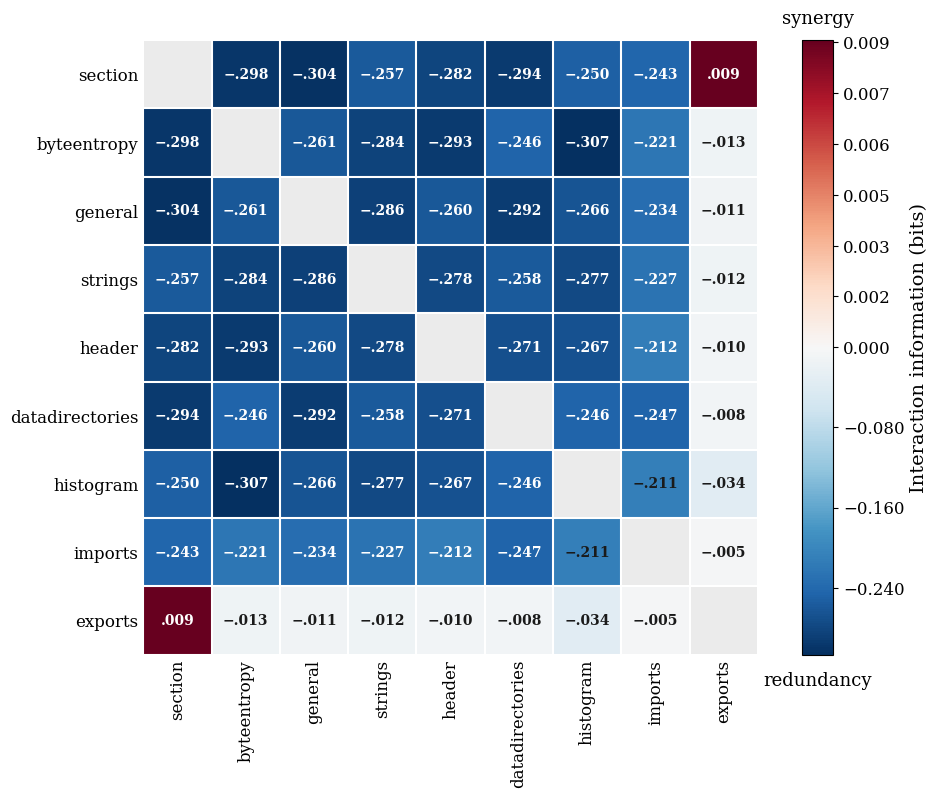

strongest synergy:    section + exports = +0.009 bits
strongest redundancy: byteentropy + histogram = -0.307 bits


In [ ]:
matplotlib.rcParams.update({
    "font.family": CFG.FIG_FONT_FAMILY, "font.size": CFG.FIG_FONT_SIZE, "mathtext.fontset": "dejavuserif",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": CFG.FIG_DPI, "savefig.bbox": "tight",
})


def save_figure(fig, name):
    for ext in CFG.FIG_FORMATS:
        fig.savefig(os.path.join(CFG.OUTPUT_DIR, f"{name}.{ext}"))
    print("saved:", ", ".join(os.path.join(CFG.OUTPUT_DIR, f"{name}.{ext}") for ext in CFG.FIG_FORMATS))


def plot_interaction_heatmap(inter, names, uniq, name):
    n = len(names)
    if CFG.HEATMAP_ORDER == "strength":
        order = np.argsort(-np.abs(inter).sum(axis=1), kind="stable")
    elif CFG.HEATMAP_ORDER == "importance":
        order = np.argsort(-uniq, kind="stable")
    else:
        order = np.arange(n)
    M = inter[np.ix_(order, order)].astype(float)
    np.fill_diagonal(M, np.nan)
    labels = [names[i] for i in order]

    vmax, vmin = max(np.nanmax(M), 1e-3), min(np.nanmin(M), -1e-3)
    norm = matplotlib.colors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)     # white is always exactly 0 bits
    cmap = matplotlib.colormaps[CFG.HEATMAP_CMAP].copy()
    cmap.set_bad(CFG.HEATMAP_DIAG_COLOR)

    side = 0.62 * n + 2.4
    fig, ax = plt.subplots(figsize=(side + 1.6, side))
    im = ax.imshow(M, cmap=cmap, norm=norm)
    ax.set_xticks(range(n), labels, rotation=90)
    ax.set_yticks(range(n), labels)
    ax.set_xticks(np.arange(-0.5, n), minor=True)
    ax.set_yticks(np.arange(-0.5, n), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            r, g, b, _ = cmap(norm(M[i, j]))
            dark = 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45
            text = f"{M[i, j]:.3f}".replace("0.", ".", 1).replace("-", "−")
            ax.text(j, i, text, ha="center", va="center", fontsize=CFG.HEATMAP_ANNOT_SIZE, fontweight="bold",
                    color="white" if dark else "#1a1a1a")

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.06)
    ticks = [t for t in matplotlib.ticker.MaxNLocator(nbins=8).tick_values(0.0, vmax) if 0.0 <= t <= vmax]
    if -vmin >= 0.25 * vmax:
        ticks = [t for t in matplotlib.ticker.MaxNLocator(nbins=4).tick_values(vmin, 0.0) if vmin <= t < 0.0] + ticks
    else:
        ticks = [vmin] + ticks
    cbar.set_ticks(ticks)
    cbar.ax.yaxis.set_major_formatter(
        matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.3f}".replace("-", "−")))
    cbar.set_label("Interaction information (bits)", fontsize=CFG.FIG_FONT_SIZE + 2)
    cbar.ax.set_title("synergy", fontsize=CFG.FIG_FONT_SIZE + 1, pad=12)
    cbar.ax.set_xlabel("redundancy", fontsize=CFG.FIG_FONT_SIZE + 1, labelpad=12)
    save_figure(fig, name)
    plt.show()
    return labels, M


heat_labels, heat_matrix = plot_interaction_heatmap(inter, GROUP_NAMES, uniq, f"interaction_heatmap_{CFG.MODEL}")
pd.DataFrame(inter, index=GROUP_NAMES, columns=GROUP_NAMES).to_csv(
    os.path.join(CFG.OUTPUT_DIR, f"interaction_bits_{CFG.MODEL}.csv"))
_a, _b = np.unravel_index(np.nanargmax(heat_matrix), heat_matrix.shape)
_c, _d = np.unravel_index(np.nanargmin(heat_matrix), heat_matrix.shape)
print(f"strongest synergy:    {heat_labels[_a]} + {heat_labels[_b]} = {heat_matrix[_a, _b]:+.3f} bits")
print(f"strongest redundancy: {heat_labels[_c]} + {heat_labels[_d]} = {heat_matrix[_c, _d]:+.3f} bits")

saved: /content/drive/MyDrive/icml/ember/results/ember2018_xai/ablation_auprc_auroc_xgboost.pdf, /content/drive/MyDrive/icml/ember/results/ember2018_xai/ablation_auprc_auroc_xgboost.png


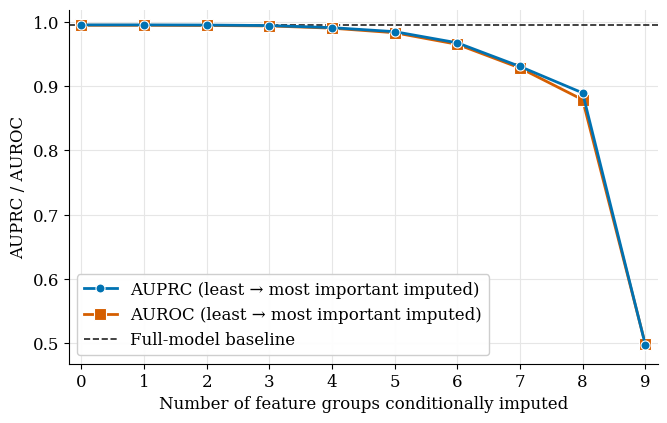

 groups_imputed  AUPRC  AUROC last_group_imputed
              0 0.9960 0.9954                   
              1 0.9960 0.9954            exports
              2 0.9958 0.9951            general
              3 0.9950 0.9944             header
              4 0.9917 0.9909            strings
              5 0.9855 0.9838        byteentropy
              6 0.9680 0.9657    datadirectories
              7 0.9311 0.9288          histogram
              8 0.8898 0.8792            imports
              9 0.4971 0.4981            section
(the 'last_group_imputed' column shows the order of seed 2026)


In [ ]:
def plot_ablation(auprc, auroc, name):
    x = np.arange(len(auprc))
    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    mk = dict(markeredgecolor="white", markeredgewidth=0.8) if CFG.ABLATION_MARKERS else {}
    ax.axhline(0.5 * (auprc[0] + auroc[0]), color=CFG.COLOR_BASELINE, linestyle="--", linewidth=1.2,
               label="Full-model baseline", zorder=1)
    ax.plot(x, auprc, color=CFG.COLOR_AUPRC, linewidth=2, marker="o" if CFG.ABLATION_MARKERS else None,
            markersize=6.5, label="AUPRC (least → most important imputed)", zorder=3, **mk)
    ax.plot(x, auroc, color=CFG.COLOR_AUROC, linewidth=2, marker="s" if CFG.ABLATION_MARKERS else None,
            markersize=8.5, label="AUROC (least → most important imputed)", zorder=2, **mk)
    ax.set_xlabel("Number of feature groups conditionally imputed")
    ax.set_ylabel("AUPRC / AUROC")
    ax.set_xticks(x if len(x) <= 12 else x[::2])
    ax.set_xlim(-0.2, x[-1] + 0.2)
    ax.set_ylim(min(0.47, min(auprc.min(), auroc.min()) - 0.03), 1.02)
    ax.grid(color="#E6E6E6", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    handles, labels_ = ax.get_legend_handles_labels()
    ax.legend(handles[1:] + handles[:1], labels_[1:] + labels_[:1], loc="lower left", frameon=True,
              framealpha=0.95, edgecolor="#CCCCCC")
    save_figure(fig, name)
    plt.show()


abl_auprc = np.mean([r["abl_auprc"] for r in results], axis=0)
abl_auroc = np.mean([r["abl_auroc"] for r in results], axis=0)
plot_ablation(abl_auprc, abl_auroc, f"ablation_auprc_auroc_{CFG.MODEL}")

ablation = pd.DataFrame({"groups_imputed": np.arange(G + 1), "AUPRC": abl_auprc, "AUROC": abl_auroc})
ablation["last_group_imputed"] = [""] + [GROUP_NAMES[int(g)] for g in results[0]["abl_order"]]
ablation.to_csv(os.path.join(CFG.OUTPUT_DIR, f"ablation_{CFG.MODEL}.csv"), index=False)
print(ablation.round(4).to_string(index=False))
print(f"(the 'last_group_imputed' column shows the order of seed {results[0]['seed']})")